# BAFAD Week 8 — Exercise 1: Streaming Drift Detection with Page-Hinkley

**Deadline:** Saturday 22 November 2026 at 23:59  
**Submission:** Push this notebook to your fork under `week08/`

---

Implement a Page-Hinkley drift detector that monitors per-window reconstruction error.
When drift is detected, the model retrains on the clean reference file (`3.csv`) and
a new anomaly threshold is computed. The monitor logs each drift event.

**What you implement:**

| Section | Task | Points |
|---|---|---|
| 5 | `PageHinkleyDetector` (full class) | 30 |
| 6 | `inject_drift()` | 10 |
| 7 | `PHDriftMonitor.__init__()` and `process_stream()` | 40 |
| 8 | Visualization | 10 |
| 9 | Interpretation (3 questions) | 5 |
| 10 | Report table + drift event log | 5 |
| **Total** | | **100** |

## Section 1 — Setup & Imports

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path

WINDOW_SIZE = 32
STEP        = 4
PERCENTILE  = 99
DATA_DIR    = Path('synthetic_alldata')   # swap to Path('SKAB/alldata') for real data
MODEL_PATH  = Path('autoencoder_week08_base.keras')

print(f'TF version: {tf.__version__}')

TF version: 2.21.0


## Section 2 — Carry-Forward Functions (Weeks 3–6)

All helper functions are provided. Do not modify them.

In [2]:
# ── Week 3 ──────────────────────────────────────────────────────────────────
def extract_anomaly_windows(labels):
    windows, in_win, start = [], False, 0
    for i, v in enumerate(labels):
        if v == 1 and not in_win:
            in_win, start = True, i
        elif v == 0 and in_win:
            windows.append((start, i)); in_win = False
    if in_win:
        windows.append((start, len(labels)))
    return windows

def inject_noise_profile(X, start, end, variance=2.5, mode='noise'):
    X = X.copy()
    if mode == 'noise':
        X[start:end] += np.random.normal(0, np.sqrt(variance), X[start:end].shape)
    elif mode == 'blackout':
        X[start:end] = 0.0
    return X

# ── Week 4 ──────────────────────────────────────────────────────────────────
def make_synthetic_skab_file(filepath, n_rows, n_features, anomaly_windows,
                              noise_variance=2.5, seed=42):
    np.random.seed(seed)
    rng = np.random.default_rng(seed)
    X = rng.standard_normal((n_rows, n_features)).astype(np.float32)
    labels = np.zeros(n_rows, dtype=int)
    for s, e in anomaly_windows:
        labels[s:e] = 1
    idx = pd.date_range('2023-01-01', periods=n_rows, freq='s')
    cols = [f'sensor_{i+1}' for i in range(n_features)]
    df = pd.DataFrame(X, index=idx, columns=cols)
    df.index.name = 'datetime'
    df['anomaly'] = labels
    df['changepoint'] = 0
    filepath.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(filepath, sep=';')
    return df

# ── Week 5 ──────────────────────────────────────────────────────────────────
def make_windows(X, window_size=32, step=4):
    windows, indices = [], []
    T = len(X)
    for start in range(0, T - window_size + 1, step):
        windows.append(X[start:start + window_size])
        indices.append(start)
    return np.array(windows, dtype=np.float32), np.array(indices, dtype=int)

def build_autoencoder(window_size, n_features):
    inp = tf.keras.Input(shape=(window_size, n_features))
    x   = tf.keras.layers.Conv1D(16, 3, activation='relu', padding='same')(inp)
    x   = tf.keras.layers.MaxPooling1D(2)(x)
    x   = tf.keras.layers.Conv1D(8, 3, activation='relu', padding='same')(x)
    x   = tf.keras.layers.MaxPooling1D(2)(x)
    x   = tf.keras.layers.Conv1D(8, 3, activation='relu', padding='same')(x)
    x   = tf.keras.layers.UpSampling1D(2)(x)
    x   = tf.keras.layers.Conv1D(16, 3, activation='relu', padding='same')(x)
    x   = tf.keras.layers.UpSampling1D(2)(x)
    out = tf.keras.layers.Conv1D(n_features, 3, activation='linear', padding='same')(x)
    model = tf.keras.Model(inp, out)
    model.compile(optimizer='adam', loss='mse')
    return model

def reconstruction_error(model, X, window_size=32, step=4):
    windows, indices = make_windows(X, window_size, step)
    preds = model.predict(windows, verbose=0)
    errors = np.mean((windows - preds) ** 2, axis=(1, 2))
    return errors, indices

# ── Week 6 ──────────────────────────────────────────────────────────────────
def set_threshold(errors_clean, percentile=99):
    return float(np.percentile(errors_clean, percentile))

def predict_anomalies(errors, indices, threshold, T, window_size):
    pred = np.zeros(T, dtype=int)
    for err, start in zip(errors, indices):
        center = start + window_size // 2
        if center < T:
            pred[center] = int(err > threshold)
    return pred

def compute_metrics(labels, pred):
    tp = int(np.sum((pred == 1) & (labels == 1)))
    fp = int(np.sum((pred == 1) & (labels == 0)))
    fn = int(np.sum((pred == 0) & (labels == 1)))
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if (precision + recall) > 0 else 0.0)
    return dict(tp=tp, fp=fp, fn=fn,
                precision=precision, recall=recall, f1=f1)

def evaluate_file(model, filepath, sensor_cols, threshold,
                  window_size=32, step=4, noise_variance=2.5, seed=42):
    df     = pd.read_csv(filepath, sep=';', index_col='datetime', parse_dates=True)
    X      = df[sensor_cols].values.astype(np.float32)
    labels = df['anomaly'].values.astype(int)
    T      = len(labels)
    anomaly_wins = extract_anomaly_windows(labels)
    np.random.seed(seed)
    X_cont = X.copy()
    for s, e in anomaly_wins:
        X_cont = inject_noise_profile(X_cont, s, e, variance=noise_variance, mode='noise')
    errors, indices = reconstruction_error(model, X_cont, window_size, step)
    pred = predict_anomalies(errors, indices, threshold, T, window_size)
    metrics = compute_metrics(labels, pred)
    metrics.update(dict(
        filename     = filepath.name,
        threshold    = round(threshold, 6),
        n_anomaly_ts = int(labels.sum()),
        n_windows    = len(errors),
    ))
    return metrics

print('All carry-forward functions defined.')

All carry-forward functions defined.


## Section 3 — Regenerate Synthetic Dataset

In [3]:
SPECS = {
    '1.csv': (800,  [(150, 230), (500, 580)]),
    '2.csv': (1000, [(200, 350)]),
    '3.csv': (600,  []),
    '4.csv': (900,  [(100, 160), (400, 480), (700, 750)]),
    '5.csv': (750,  [(300, 420)]),
}
N_FEATURES = 8

for fname, (n_rows, wins) in SPECS.items():
    make_synthetic_skab_file(DATA_DIR / fname, n_rows, N_FEATURES, wins)

sample_df   = pd.read_csv(DATA_DIR / '3.csv', sep=';', index_col='datetime', parse_dates=True)
sensor_cols = [c for c in sample_df.columns if c.startswith('sensor_')]
print(f'Sensor columns ({len(sensor_cols)}): {sensor_cols}')
print('Dataset regenerated.')

Sensor columns (8): ['sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8']
Dataset regenerated.


## Section 4 — Train Base Model & Compute Threshold

In [4]:
if MODEL_PATH.exists():
    model = tf.keras.models.load_model(MODEL_PATH)
    print(f'Loaded base model from {MODEL_PATH}')
else:
    print('Training base model on 3.csv (clean) ...')
    np.random.seed(42); tf.random.set_seed(42)
    df3    = pd.read_csv(DATA_DIR / '3.csv', sep=';', index_col='datetime', parse_dates=True)
    X3     = df3[sensor_cols].values.astype(np.float32)
    wins3, _ = make_windows(X3, WINDOW_SIZE, STEP)
    model = build_autoencoder(WINDOW_SIZE, len(sensor_cols))
    model.fit(wins3, wins3, epochs=15, batch_size=16,
              validation_split=0.1, verbose=1)
    model.save(MODEL_PATH)
    print(f'Base model saved to {MODEL_PATH}')

df3      = pd.read_csv(DATA_DIR / '3.csv', sep=';', index_col='datetime', parse_dates=True)
X3       = df3[sensor_cols].values.astype(np.float32)
errors_train, _ = reconstruction_error(model, X3, WINDOW_SIZE, STEP)
THRESHOLD = set_threshold(errors_train, PERCENTILE)
print(f'\n{PERCENTILE}th-percentile threshold: {THRESHOLD:.6f}')

Training base model on 3.csv (clean) ...
Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - loss: 1.0148 - val_loss: 1.0109
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 1.0016 - val_loss: 1.0078
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.9957 - val_loss: 1.0059
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.9900 - val_loss: 1.0049
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.9840 - val_loss: 1.0028
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.9771 - val_loss: 0.9989
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.9694 - val_loss: 0.9946
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.9602 - val_loss: 0.9894
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.9501 - val_loss: 0.9844
Epoch 10/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.9397 - val_loss: 0.9807
Epoch 11/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.9300 - val_loss: 0.9787
Epoch 12/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms

## Section 5 — Implement `PageHinkleyDetector` *(30 pts)*

Implement the class below.  Read the lecture and the resource guide before you start.

**Algorithm:**

$$U_t = \sum_{i=1}^{t} (x_i - \mu_t - \delta) \qquad m_t = \min_{i \leq t} U_i$$

**Drift detected** when $U_t - m_t > \lambda$.

**`reset()` must clear:** `self.n`, `self.sum`, `self.U`, `self.m` (all to 0.0 / 0).  
**`update(x)` must:** increment `n`, update running sum, compute `mu`, update `U` and `m`, return the detection boolean.

The sanity-check assertions at the bottom of the cell must both pass before you proceed.

In [17]:
class PageHinkleyDetector:
    """
    Page-Hinkley sequential change-point detector for upward shift.

    Tracks the cumulative deviation U_t = Σ(x_i − μ_i − δ) and fires when
    U_t has risen significantly above its running minimum:
        U_t − m_t > λ
    """

    def __init__(self, delta=0.005, lambda_=50.0):
        self.delta   = delta
        self.lambda_ = lambda_
        self.reset()

    def reset(self):
        """Restart cumulative statistics — call after each drift event."""
        # TODO: initialise self.n, self.sum, self.U, self.m
        self.n = 0
        self.sum = 0.0
        self.U = 0.0
        self.m = 0.0



    def update(self, x):
        """
        Feed one observation.

        Parameters
        ----------
        x : float — reconstruction error for one window

        Returns
        -------
        bool — True if drift detected
        """
        # TODO: update n, sum, compute running mean mu
        #       update U += x - mu - self.delta
        #       update m  = min(m, U)
        #       return (U - m) > lambda_
        self.n += 1
        self.sum += x
        mu = self.sum / self.n
        self.U += x - mu - self.delta
        self.m = min(self.m, self.U)
        return (self.U - self.m) > self.lambda_



# ── Sanity check — do not modify ────────────────────────────────────────────
ph_test = PageHinkleyDetector(delta=0.005, lambda_=50.0)

# Flat stream: no drift expected
drift_flags = [ph_test.update(1.0) for _ in range(200)]
assert not any(drift_flags), 'PH fired on flat stream — check lambda_'

# Step-up stream: drift must fire
ph_test.reset()
drift_flags  = [ph_test.update(1.0) for _ in range(100)]
drift_flags += [ph_test.update(5.0) for _ in range(200)]
assert any(drift_flags), 'PH did not fire on step-up stream — check update logic'
first_fire = next(i for i, v in enumerate(drift_flags) if v)
print(f'PageHinkleyDetector sanity checks passed. Step-up drift detected at observation {first_fire}.')

PageHinkleyDetector sanity checks passed. Step-up drift detected at observation 113.


## Section 6 — Implement `inject_drift()` *(10 pts)*

Add a constant `magnitude` to every feature from `start_ts` onward.  
Return a **copy** — do not modify the original array.

In [6]:
def inject_drift(X, start_ts, magnitude=1.5):
    """
    Inject a sustained baseline shift into a sensor array.

    Parameters
    ----------
    X         : np.ndarray shape (T, F)
    start_ts  : int — first timestep affected
    magnitude : float — value added to every feature after start_ts

    Returns
    -------
    np.ndarray — copy of X with drift injected (original unchanged)
    """
    # TODO: copy X, add magnitude to X_copy[start_ts:]
    X_copy = X.copy()
    X_copy[start_ts:] += magnitude
    return X_copy



# Sanity check — do not modify
X_test = np.zeros((10, 3), dtype=np.float32)
X_d    = inject_drift(X_test, start_ts=5, magnitude=2.0)
assert np.allclose(X_d[:5], 0.0), 'Pre-drift region modified'
assert np.allclose(X_d[5:], 2.0), 'Post-drift region wrong'
print('inject_drift() sanity check passed.')

inject_drift() sanity check passed.


## Section 7 — Implement `PHDriftMonitor` *(40 pts)*

Complete `__init__` (store all arguments; create `self.ph`) and `process_stream`.

**`process_stream(X)` logic:**
1. Slide a window of `window_size` with step `step` over X.
2. For each window: compute reconstruction error (MSE); call `ph.update(error)`.
3. If drift detected:
   - Record `window_start`, `old_threshold`, `n_windows_since_reset = ph.n`.
   - Call `self.refit_on_clean()` — this updates `self.model` and `self.threshold` in place.
   - Call `self.ph.reset()`.
   - Append updated event dict with `new_threshold`.
4. Return `(drift_events, self.threshold, errors_log)`.

`refit_on_clean()` is provided — do not modify it.

In [20]:

class PHDriftMonitor:
    """Stateful streaming drift monitor (Page-Hinkley + adaptive retraining)."""

    def __init__(self, model, sensor_cols, threshold,
                 window_size=32, step=4,
                 delta=0.005, lambda_=50.0,
                 retrain_file=None, seed=42):

        # Store all arguments as instance attributes
        self.model = model
        self.sensor_cols = sensor_cols
        self.threshold = threshold
        self.window_size = window_size
        self.step = step
        self.delta = delta
        self.lambda_ = lambda_
        self.retrain_file = retrain_file
        self.seed = seed

        self.ph = PageHinkleyDetector(delta=delta, lambda_=lambda_)

    def refit_on_clean(self):
        """Retrain model on clean reference file and recompute threshold."""
        df = pd.read_csv(self.retrain_file, sep=';',
                         index_col='datetime', parse_dates=True)
        X = df[self.sensor_cols].values.astype(np.float32)
        windows, _ = make_windows(X, self.window_size, self.step)
        np.random.seed(self.seed)
        tf.random.set_seed(self.seed)
        self.model.fit(windows, windows,
                       epochs=10, batch_size=16,
                       validation_split=0.1, verbose=0)
        errors, _ = reconstruction_error(
            self.model, X, self.window_size, self.step
        )
        self.threshold = set_threshold(errors, PERCENTILE)

    def process_stream(self, X):
        """
        Process a 2D sensor array (T, F) one window at a time.

        Returns
        -------
        drift_events    : list[dict] — one entry per drift detection
        final_threshold : float
        errors_log      : list[float] — reconstruction error per window
        """

        # Initialize lists
        drift_events = []
        errors_log = []
        T = len(X)

        # Process each sliding window
        for start in range(0, T - self.window_size + 1, self.step):
            window = X[start:start + self.window_size]
            window = np.expand_dims(window, axis=0)

            # Predict and calculate reconstruction error
            prediction = self.model.predict(window, verbose=0)
            error = float(np.mean((window - prediction) ** 2))
            errors_log.append(error)

            # Check for drift
            if self.ph.update(error):
                event = {
                    'window_start': start,
                    'old_threshold': self.threshold,
                    'n_windows_since_reset': self.ph.n
                }

                # Retrain on clean data and reset detector
                self.refit_on_clean()
                self.ph.reset()

                # Record updated threshold
                event['new_threshold'] = self.threshold
                drift_events.append(event)

        return drift_events, self.threshold, errors_log


print('PHDriftMonitor class defined.')


PHDriftMonitor class defined.


## Section 8 — Run Drift Monitor on 4.csv with Injected Drift

In [27]:

# Load 4.csv and inject a sustained drift at timestep 400
DRIFT_TS = 400
DRIFT_MAG = 1.5

df4 = pd.read_csv(
    DATA_DIR / '4.csv',
    sep=';',
    index_col='datetime',
    parse_dates=True
)

X4_raw = df4[sensor_cols].values.astype(np.float32)
X4_drift = inject_drift(
    X4_raw,
    start_ts=DRIFT_TS,
    magnitude=DRIFT_MAG
)

print(f'4.csv: {len(X4_raw)} timesteps')
print(f'Drift injected at timestep {DRIFT_TS} (magnitude={DRIFT_MAG})')
print('Running PHDriftMonitor (delta=0.005, lambda_=10.0) ...')

# Initialize drift monitor
monitor = PHDriftMonitor(
    model=model,
    sensor_cols=sensor_cols,
    threshold=THRESHOLD,
    window_size=WINDOW_SIZE,
    step=STEP,
    delta=0.005,
    lambda_=10.0,
    retrain_file=DATA_DIR / '3.csv',
    seed=42,
)

# Process the data stream
drift_events, final_threshold, errors_log = monitor.process_stream(X4_drift)

# Display results
print(f'\nDrift events detected: {len(drift_events)}')
print(f'Final threshold: {final_threshold:.6f}')

# Display detected drift events
for ev in drift_events:
    print(ev)

# Assertions — all must pass before submission
assert len(drift_events) >= 1, 'No drift events detected'

for ev in drift_events:
    assert ev['window_start'] > DRIFT_TS, \
        f"Drift detected before injection at window_start={ev['window_start']}"

print('All drift monitor assertions passed.')




4.csv: 900 timesteps
Drift injected at timestep 400 (magnitude=1.5)
Running PHDriftMonitor (delta=0.005, lambda_=10.0) ...

Drift events detected: 2
Final threshold: 1.180815
{'window_start': 404, 'old_threshold': 1.061972975730896, 'n_windows_since_reset': 102, 'new_threshold': 1.1750431060791016}
{'window_start': 740, 'old_threshold': 1.1750431060791016, 'n_windows_since_reset': 84, 'new_threshold': 1.1808147430419922}
All drift monitor assertions passed.


## Section 8 — Visualization *(10 pts)*

Produce a two-panel figure:

- **Panel 1:** `sensor_1` values — original vs. drifted, with a vertical line at the drift injection point.
- **Panel 2:** Reconstruction error per window, initial threshold (dashed), drift event markers (vertical lines), and updated thresholds.

Save the figure as `week08_exercise1_plot.png`.

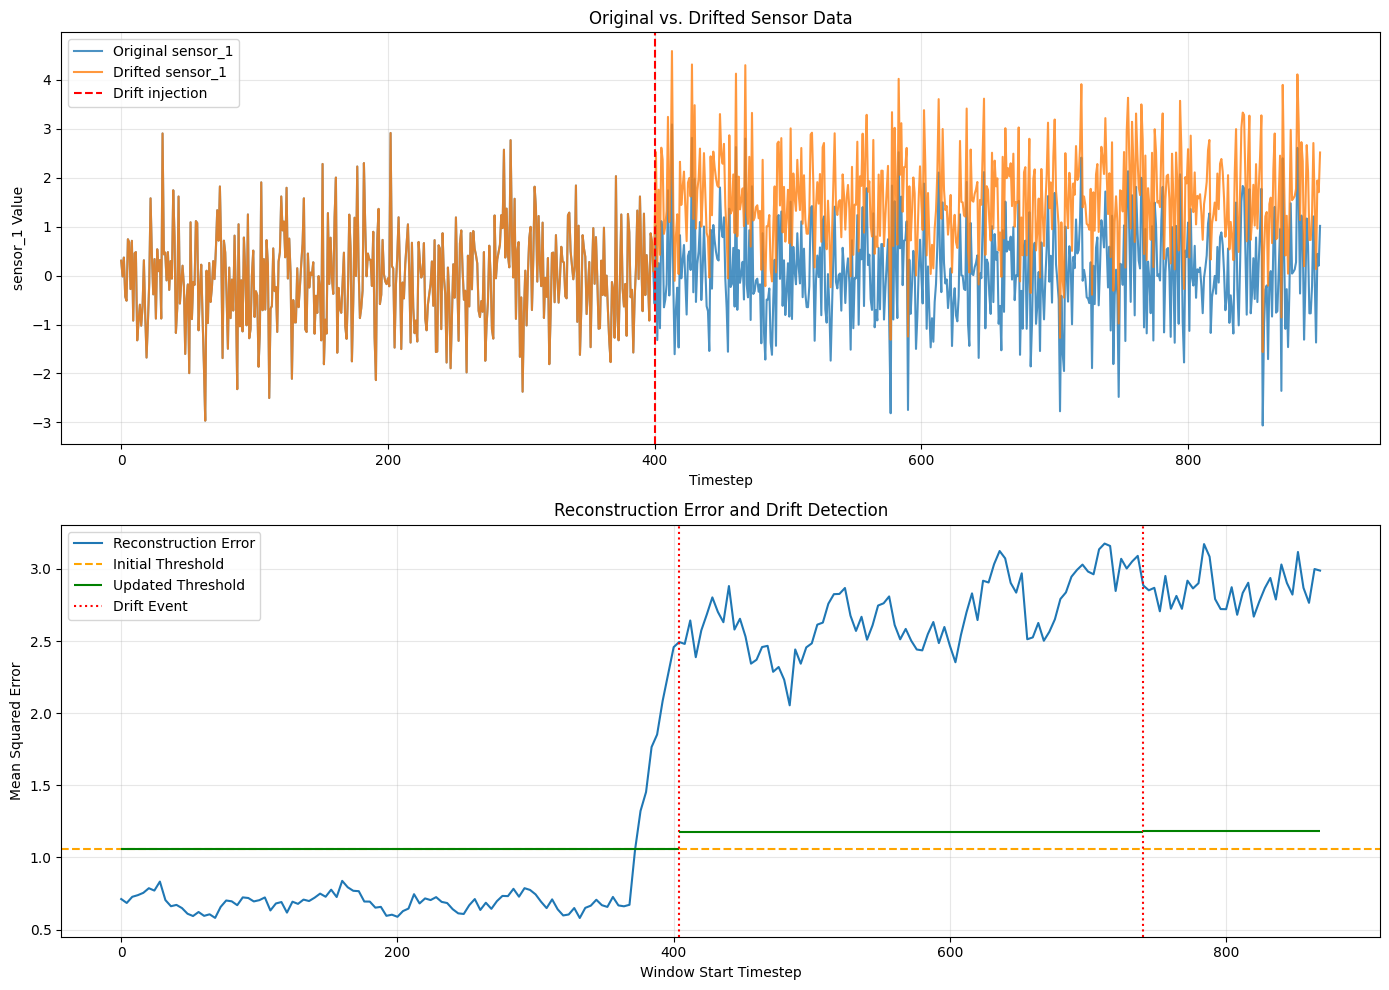

Figure saved as week08_exercise1_plot.png


In [28]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

sensor_idx = sensor_cols.index('sensor_1')
timesteps = np.arange(len(X4_raw))

axes[0].plot(timesteps, X4_raw[:, sensor_idx],
             label='Original sensor_1', alpha=0.8)
axes[0].plot(timesteps, X4_drift[:, sensor_idx],
             label='Drifted sensor_1', alpha=0.8)

axes[0].axvline(DRIFT_TS, color='red',
                linestyle='--', label='Drift injection')

axes[0].set_title('Original vs. Drifted Sensor Data')
axes[0].set_xlabel('Timestep')
axes[0].set_ylabel('sensor_1 Value')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

window_starts = np.arange(
    0,
    len(X4_drift) - WINDOW_SIZE + 1,
    STEP
)

axes[1].plot(window_starts, errors_log,
             label='Reconstruction Error')

axes[1].axhline(THRESHOLD, color='orange',
                linestyle='--', label='Initial Threshold')

current_threshold = THRESHOLD
previous_start = window_starts[0]

for i, event in enumerate(drift_events):
    event_start = event['window_start']

    axes[1].hlines(
        current_threshold,
        previous_start,
        event_start,
        colors='green',
        linestyles='-',
        label='Updated Threshold' if i == 0 else None
    )

    axes[1].axvline(
        event_start,
        color='red',
        linestyle=':',
        label='Drift Event' if i == 0 else None
    )

    current_threshold = event['new_threshold']
    previous_start = event_start

axes[1].hlines(
    current_threshold,
    previous_start,
    window_starts[-1],
    colors='green',
    linestyles='-',
    label='Updated Threshold' if not drift_events else None
)

axes[1].set_title('Reconstruction Error and Drift Detection')
axes[1].set_xlabel('Window Start Timestep')
axes[1].set_ylabel('Mean Squared Error')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig('week08_exercise1_plot.png', dpi=300,
            bbox_inches='tight')

plt.show()

print('Figure saved as week08_exercise1_plot.png')


## Section 9 — Interpretation Questions *(5 pts)*

Answer in the cells below (2–4 sentences each).

**Q1.** Why does the PH test use $U_t - m_t$ rather than $U_t$ alone as its detection statistic?

*The PH test uses it because it helps show how much the error has increased from its lowest point. Instead of just looking at the total error it looks for changes that could mean drift is happening. This makes it easier to detect when something changes in the data.*

---

**Q2.** After a drift event, `PHDriftMonitor` calls `ph.reset()`. Why is this necessary?
What would happen if you did not reset?

*Resetting the PH detector is important because it allows the system to start over after detecting drift. If we didn't reset it, the previous errors could affect future results and cause the system to detect drift when there isn't any. This helps make sure each new drift event is detected correctly.*

---

**Q3.** In the federated setting (Week 7), a drift event detected by Client 0 should
ideally trigger a new global round. Sketch (in words) how you would modify
`BAFADClient.fit()` to initiate a retraining request after local drift detection.

*I would change BAFADClient.fit() so that when Client 0 detects drift it lets the server know that the model needs to be retrained. The server could then start another global training round so the clients can update their models. This would help the model adjust to the new data and improve its accuracy.*

## Section 10 — Report Table + Drift Event Log *(5 pts)*

In [29]:
# Print drift event log
print('=== Drift Event Log ===')
df_events = pd.DataFrame(drift_events)
print(df_events.to_string(index=False))
print()

# Post-drift scorecard
print('=== Post-Drift Scorecard (after final retraining) ===')
scorecard = []
for fpath in sorted(DATA_DIR.glob('*.csv')):
    m = evaluate_file(monitor.model, fpath, sensor_cols,
                      monitor.threshold, WINDOW_SIZE, STEP)
    scorecard.append(m)
df_sc = pd.DataFrame(scorecard)
print(df_sc[['filename', 'n_anomaly_ts', 'precision', 'recall', 'f1']].to_string(index=False))

# Assertions
f1s = df_sc.set_index('filename')['f1'].to_dict()
assert f1s['3.csv'] == 0.0, f"3.csv F1 must be 0.0, got {f1s['3.csv']}"
assert any(v > 0 for k, v in f1s.items() if k != '3.csv'), \
    'At least one anomalous file must have F1 > 0 after drift adaptation'
print('\nPost-drift scorecard assertions passed.')

=== Drift Event Log ===
 window_start  old_threshold  n_windows_since_reset  new_threshold
          404       1.061973                    102       1.175043
          740       1.175043                     84       1.180815

=== Post-Drift Scorecard (after final retraining) ===
filename  n_anomaly_ts  precision   recall       f1
   1.csv           160   0.571429 0.250000 0.347826
   2.csv           150   0.567164 0.253333 0.350230
   3.csv             0   0.000000 0.000000 0.000000
   4.csv           190   0.615385 0.252632 0.358209
   5.csv           120   0.625000 0.250000 0.357143

Post-drift scorecard assertions passed.


## Section 11 — Submission Checklist

- [ ] All sanity-check assertions pass (Sections 5 and 6)
- [ ] All drift monitor assertions pass (Section 8)
- [ ] `week08_exercise1_plot.png` is saved and visible in Section 8
- [ ] All three interpretation questions answered (Section 9)
- [ ] Post-drift scorecard assertions pass (Section 10)
- [ ] Push notebook to your fork under `week08/`